# Satellite Terrain Classification with ResNet-9

**Author:** Ibrahim Uthman Muhammad

This notebook contains the complete training pipeline for classifying Sentinel-2 satellite imagery into 10 land-use categories (EuroSAT dataset). The architecture uses a custom PyTorch ResNet-9 model trained with AdamW and OneCycleLR scheduling, reaching 96% accuracy on a blind evaluation dataset.

In [ ]:
#libraries used
import numpy as np
import torch
import matplotlib.pyplot as plt
import os
import pandas as pd
from PIL import Image 
from sklearn.model_selection import train_test_split
import seaborn as sns
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torchvision.transforms as transforms   
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix as confusion_matrix, ConfusionMatrixDisplay as CMD    
from copy import deepcopy
from torch.optim.lr_scheduler import OneCycleLR




# Setting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.backends.mps.is_available():
    device = torch.device("mps")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [ ]:
# Helper function to make sure results are reproducible 
def set_seed(seed=42):
    import random, numpy as np, torch, os
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(42)

In [2]:
# checking successful setup
print(f"Using device: {device}")

Using device: cpu


In [4]:
# For visualization in Jupyter notebooks
%matplotlib inline

In [4]:
# creating folder 'assets' if necessary
os.makedirs("assets/plots", exist_ok=True)
os.makedirs("assets/weights", exist_ok=True)

## Data Handling and Pre-Processing

In [ ]:
dataset_path = (".Data Sets-20260516/data")
def preprocess(data_folder: str) -> tuple[pd.DataFrame, dict]:
    label_dict = {
        'HerbaceousVegetation': 0, 
        'AnnualCrop': 1, 
        'Residential': 2,
        'Pasture': 3,
        'Industrial': 4,
        'River': 5,
        'Highway': 6,
        'Forest': 7,
        'PermanentCrop': 8,
        'SeaLake': 9
    }
    
    folder_path = []
    file_name = []
    labels = []
    
   
    folders = os.listdir(data_folder) 
  
    for folder in folders:
        path = os.path.join(data_folder, folder) 
        
   
        if os.path.isdir(path) and folder in label_dict:
            current_label = label_dict[folder]
            images = os.listdir(path)
            
            for image in images:
                labels.append(current_label)
                file_name.append(image)
                folder_path.append(path)
                
    df = pd.DataFrame({"folder": folder_path, "file_name": file_name, "label": labels}) 
    

    return df, label_dict



In [ ]:
# checking successful dataframe loading
dataset, label_dict = preprocess(data_folder=dataset_path) #capture in a variable ALWAYS

print(f"Length of dataset: {len(dataset)}") # Should be 10000

Length of dataset: 10000


In [ ]:
X = dataset[["folder", "file_name"]]
y = dataset["label"]
train_X, val_X, train_y, val_y = train_test_split(X, y,
                                                test_size=0.2,
                                                random_state=42,
                                                stratify=y) 
#stratify reflects proportions from the dataset to ensure classes with fewer samples are not left out completely.

train_df = pd.concat([train_X, train_y], axis=1).reset_index(drop=True)
val_df = pd.concat([val_X, val_y], axis=1).reset_index(drop=True)

print(f"Training metadata shape: {train_df.shape}")
print(f"Validation metadata shape: {val_df.shape}")

Training metadata shape: (8000, 3)
Validation metadata shape: (2000, 3)


## Exploratory Data Analysis (EDA)

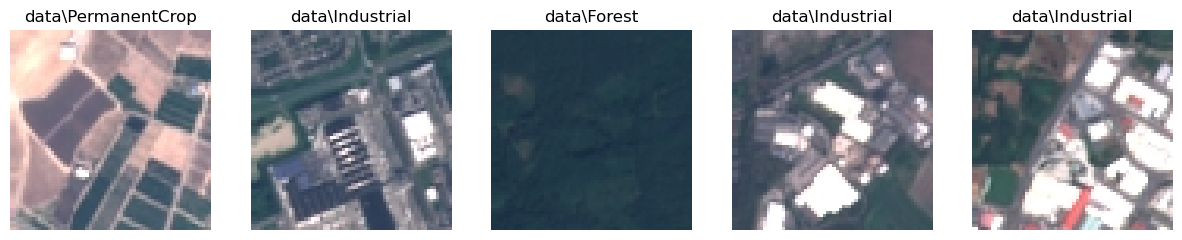

In [ ]:
def show_samples(df: pd.DataFrame, num_samples: int = 5) -> None:
    train_samples = df.sample(n=num_samples, random_state=42)
    
    fig, axes = plt.subplots(1, num_samples, figsize=(num_samples * 3, 3))

    for i, (index, row) in enumerate(train_samples.iterrows()):
        full_path = os.path.join(row["folder"], row["file_name"])
        image = Image.open(full_path)
        axes[i].imshow(image)
        axes[i].set_title(row["folder"].split('/')[-1])
        axes[i].axis("off")
        

show_samples(dataset)

    
        

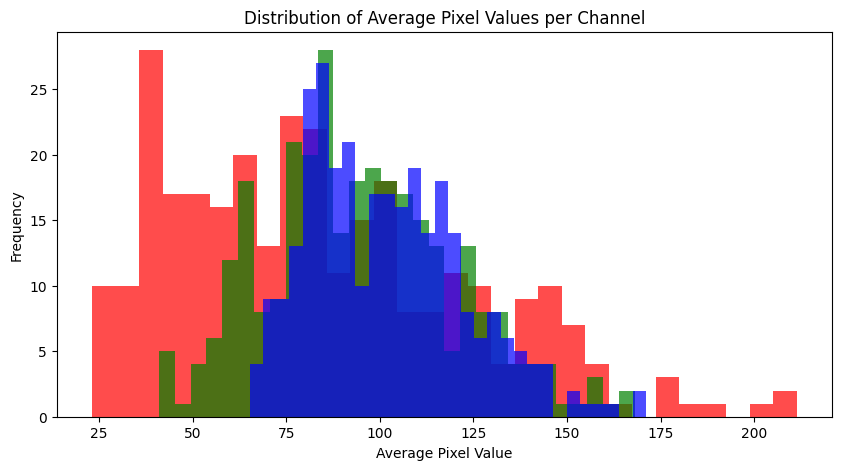

In [ ]:
def average_pixel_plot(df: pd.DataFrame) -> None: 
    mean_red = []
    mean_green = []
    mean_blue = []

    for _, row in df.iterrows():                #faster to test with .....in df.sample(n=..., random_state=42).iterrows():
        path = os.path.join(row["folder"], row["file_name"])
        with Image.open(path) as image:
            image_array = np.array(image)

            if  image_array.ndim == 3:
                mean_red.append(np.mean(image_array[:, :, 0]))
                mean_blue.append(np.mean(image_array[:, :, 2]))
                mean_green.append(np.mean(image_array[:, :, 1]))
        
    plt.figure(figsize=(10, 5)) #setup fig first, else plot will be overwritten!!!!!
    plt.title("Distribution of Average Pixel Values per Channel")
    plt.xlabel("Average Pixel Value")
    plt.ylabel("Frequency")

    #alpha in .hist() controls how transparent the graphs look
    #(good for overlapping histograms)
   
    plt.hist(mean_red, bins=30, color="red", alpha=0.7)
    plt.hist(mean_green, bins=30, color="green", alpha=0.7)
    plt.hist(mean_blue, bins=30, color="blue", alpha=0.7)

    plt.savefig("assets/plots/average_pixel_distribution.png")
        
       
        

average_pixel_plot(train_df)
    


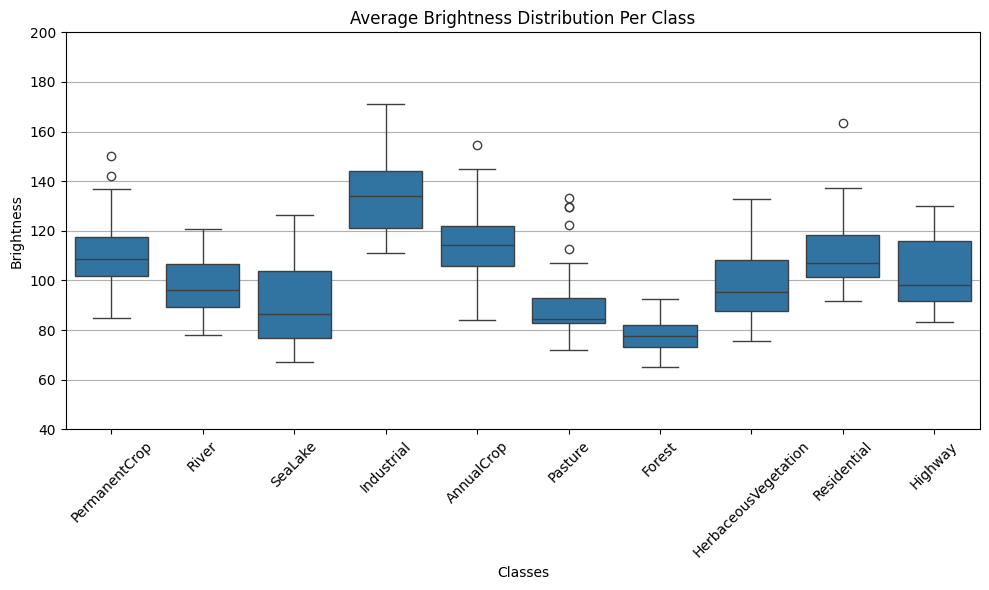

In [ ]:
def average_brightness_per_class(df: pd.DataFrame) -> None:
    brightness_data = []

    for _, row in df.iterrows():
        path = os.path.join(row["folder"], row["file_name"])
        with Image.open(path) as image: 
            image_array = np.array(image)
            if image_array.ndim == 3:
                brightness = (np.mean(image_array[:, :, 2]))
                brightness_data.append({"Classes": row["folder"].split("/")[2], "Brightness": brightness})

    brightness_df = pd.DataFrame(brightness_data)   #Only required once. (Note))


#initially used matplotlib but that would require manually computing percentiles. 
#Seaborn handles all computations for a boxplot
    plt.figure(figsize=(10, 6))
    plt.grid()
    ax = sns.boxplot(data=brightness_df, x="Classes", y="Brightness")
    plt.title("Average Brightness Distribution Per Class")
    plt.xticks(rotation=45)
    plt.tight_layout()
    ax.set(ylim=(40, 200))

    plt.savefig("assets/plots/average_brightness.png")

average_brightness_per_class(train_df)


## CNN Implementation and Training

### Dataset class

In [ ]:
class SatelliteDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, root_dir, transform=None):
    
        self.dataframe = dataframe
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        folder_name = self.dataframe.iloc[index]['folder']                               #Full file path for the image
        file_name = self.dataframe.iloc[index]['file_name']
        img_path = os.path.join(self.root_dir, folder_name, file_name)
        image = Image.open(img_path).convert("RGB")                                       #RGB since files are coloured
        label = int(self.dataframe.iloc[index]['label'])
        
        if self.transform:
            image = self.transform(image)
            
        return image, label
    



train_transforms = transforms.Compose([
    transforms.RandomCrop(64, padding=4, padding_mode="reflect"),                        #Data Augmentations
    transforms.RandomAdjustSharpness(sharpness_factor=2, p=0.5),                           # Only on training data
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=90),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),        #Important since there are many outliers in 
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.85, 1.15)),          #Average_brightness_plot

    transforms.ToTensor(), # Converts PIL image to Tensor and scales to [0, 1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1))

])

val_transforms = transforms.Compose([
    transforms.ToTensor(), 
    transforms.Normalize(mean=[0.485, 0.456, 0.406],                        #Remmeber: ImageNet
                         std=[0.229, 0.224, 0.225]),

])


### Data Loaders

In [ ]:

IMAGE_DIR = '.'                          #Struggled with double path issue. Solved


train_dataset = SatelliteDataset(dataframe=train_df, root_dir=IMAGE_DIR, transform=train_transforms)
val_dataset = SatelliteDataset(dataframe=val_df, root_dir=IMAGE_DIR, transform=val_transforms)


train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)


print(f"Training images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")



Training images: 8000
Validation images: 2000


### Model Architecture

In [ ]:
"""
3-layer CNN commented out because it failed to cross 89% Accuracy
Even with Data Augmentations, Regularization, Dropout....
"""
# class SatelliteCNN(nn.Module):
#     def __init__(self):
#         super(SatelliteCNN, self).__init__()

#         self.conv_stack = nn.Sequential(
#             nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
#             nn.BatchNorm2d(16),
#             nn.ReLU(),
#             nn.MaxPool2d(kernel_size=2, stride=2),
#             nn.Conv2d(16, 32, kernel_size=3, padding=1),
#             nn.BatchNorm2d(32),
#             nn.ReLU(),
#             nn.MaxPool2d(kernel_size=2, stride=2),
#             nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
#             nn.BatchNorm2d(64),
#             nn.ReLU(),
#             nn.MaxPool2d(kernel_size=2, stride=2),
#         )

#         self.flatten = nn.Flatten()

#         self.linear_stack = nn.Sequential(
#             nn.Dropout(0.2),
#             nn.Linear(64 * 8 * 8, 256),
#             nn.ReLU(),
#             nn.Linear(256, 10)
#         )

#     def forward(self, x):
#         x = self.conv_stack(x)
#         x = self.flatten(x)
#         logits = self.linear_stack(x)
#         return logits



def conv_block(in_channels, out_channels, pool=False):
    layers = [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    ]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class SatelliteResNet9(nn.Module):
    '''
Switched to a Resnet-9 CNN architecture. Inspired from several Kaggle notebooks where it was applied to the CIFAR-10 dataset
and even a two class satellite image classification problem. 
    '''
    def __init__(self, in_channels=3, num_classes=10):
        super().__init__()

        self.prep = conv_block(in_channels, 64)
        self.layer1 = conv_block(64, 128, pool=True)
        self.res1 = nn.Sequential(
            conv_block(128, 128),
            conv_block(128, 128)
        )

        self.layer2 = conv_block(128, 256, pool=True)
        self.layer3 = conv_block(256, 512, pool=True)
        self.res2 = nn.Sequential(
            conv_block(512, 512),
            conv_block(512, 512)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        out = self.prep(x)
        out = self.layer1(out)
        out = out + self.res1(out)
        out = self.layer2(out)

        
        
        out = self.layer3(out) #

        out = out + self.res2(out)
        out = self.classifier(out)
        return out

#Instance of the model
model = SatelliteResNet9(in_channels=3, num_classes=10).to(device)
print(f"Loaded SatelliteResNet9 on {device}")


Loaded SatelliteResNet9 on cpu


### Training Loop

In [ ]:
num_epochs = 50         
MAX_LR = 0.01
WEIGHT_DECAY = 1e-3

loss_func = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)     #AdamW over Adam

scheduler = OneCycleLR(
    optimizer,
    max_lr=MAX_LR,
    epochs=num_epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.3,
    anneal_strategy='cos'
)

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

patience = 8
epochs_no_improve = 0
best_val_loss = float("inf")
best_model_weights = deepcopy(model.state_dict())

print("Training with Early Stopping...")

for epoch in range(num_epochs):
    # --- TRAINING ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        pred = model(images)
        loss = loss_func(pred, labels)

        loss.backward()

        # Gradient clipping for stability
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step() # Step scheduler per batch

        running_loss += loss.item() * labels.size(0)

        predicted_classes = pred.argmax(1)
        total_train += labels.size(0)
        correct_train += (predicted_classes == labels).sum().item()

    avg_train_loss = running_loss / total_train
    train_accuracy = (correct_train / total_train) * 100

    # --- VALIDATION ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            pred = model(images)
            loss = loss_func(pred, labels)

            val_loss += loss.item() * labels.size(0)
            predicted_classes = pred.argmax(1)
            val_correct += (predicted_classes == labels).sum().item()
            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_accuracy = (val_correct / val_total) * 100

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)
    train_accuracies.append(train_accuracy)

    print(f"Epoch {epoch+1:02d}/{num_epochs}  | Train Loss: {avg_train_loss:.4f} | Train Acc: {train_accuracy:.2f}% | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_accuracy:.2f}%")

    # --- EARLY STOPPING ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_weights = deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nEarly stopping started at Epoch {epoch+1}!")
            break

print("----------------------------------------------")
print(f"Training Complete! Best Validation Loss: {best_val_loss:.4f}")

# Load the best weights and save them securely
model.load_state_dict(best_model_weights)
torch.save(model.state_dict(), ".assets/weights/best_satellite_cnn.pth")
print("best model weights saved to '.assets/weights/best_satellite_cnn.pth'")


Training with Early Stopping...
Epoch 01/50  | Train Loss: 1.6018 | Train Acc: 49.51% | Val Loss: 1.3842 | Val Acc: 61.15%
Epoch 02/50  | Train Loss: 1.4121 | Train Acc: 58.89% | Val Loss: 1.6402 | Val Acc: 58.05%
Epoch 03/50  | Train Loss: 1.3613 | Train Acc: 61.78% | Val Loss: 1.2232 | Val Acc: 69.50%
Epoch 04/50  | Train Loss: 1.3496 | Train Acc: 62.34% | Val Loss: 1.7039 | Val Acc: 57.80%
Epoch 05/50  | Train Loss: 1.3091 | Train Acc: 64.15% | Val Loss: 1.2061 | Val Acc: 67.80%
Epoch 06/50  | Train Loss: 1.2446 | Train Acc: 68.65% | Val Loss: 1.2098 | Val Acc: 72.70%
Epoch 07/50  | Train Loss: 1.2617 | Train Acc: 67.92% | Val Loss: 1.3507 | Val Acc: 70.45%
Epoch 08/50  | Train Loss: 1.1875 | Train Acc: 71.20% | Val Loss: 1.4071 | Val Acc: 67.30%
Epoch 09/50  | Train Loss: 1.1683 | Train Acc: 72.19% | Val Loss: 1.3177 | Val Acc: 69.65%
Epoch 10/50  | Train Loss: 1.1010 | Train Acc: 75.48% | Val Loss: 1.1793 | Val Acc: 72.85%
Epoch 11/50  | Train Loss: 1.0225 | Train Acc: 78.65% | Va

## Model Evaluation

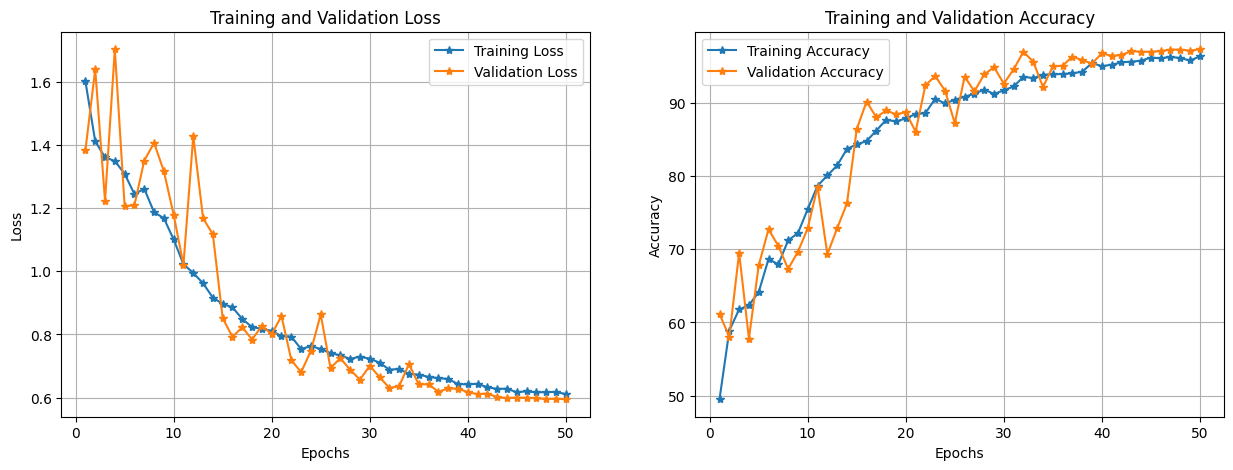

<Figure size 1000x500 with 0 Axes>

In [ ]:
epochs_range = range(1, len(train_losses) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

plt.figure(figsize=(10, 5))
ax1.plot(epochs_range, train_losses, label="Training Loss", marker="*")
ax1.plot(epochs_range, val_losses, label="Validation Loss", marker="*")
ax1.set_title("Training and Validation Loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
#ax1.set_xticks(epochs_range)     ##uncomment and set range if you would like more information about a certain epoch range. Left uncommented for readability
ax1.legend()
ax1.grid(True)



epochs_range = range(1, len(train_losses) + 1)

ax2.plot(epochs_range, train_accuracies, label="Training Accuracy", marker="*")
ax2.plot(epochs_range, val_accuracies, label="Validation Accuracy", marker="*")
ax2.set_title("Training and Validation Accuracy")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Accuracy")
#ax2.set_xticks(epochs_range)     #uncomment and set range if you would like more information about a certain epoch range. Left uncommented for readability
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

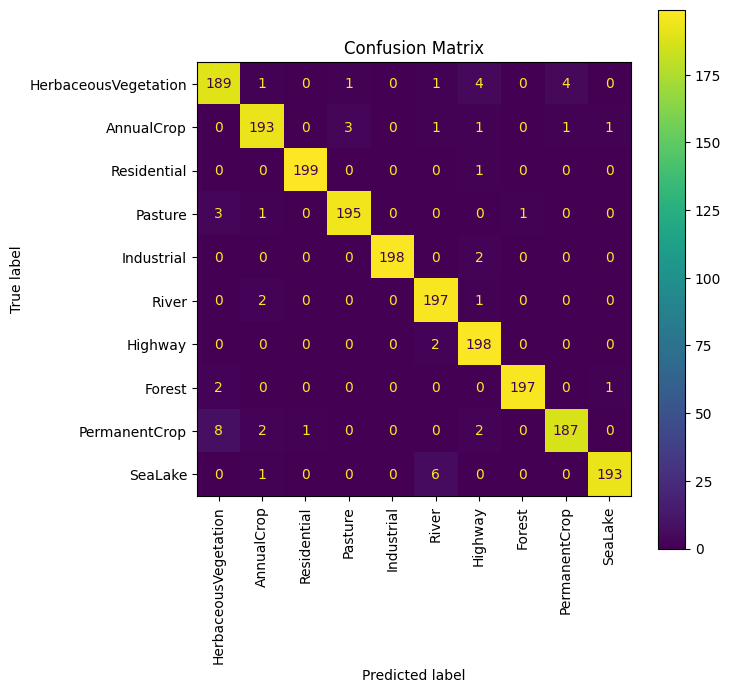

In [ ]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        pred = model(images)
        predicted_classes = pred.argmax(1)

        
        all_preds.extend(predicted_classes.cpu().numpy())
        all_labels.extend(labels.numpy())

fig, ax = plt.subplots(figsize=(7, 7))

cm = confusion_matrix(all_labels, all_preds, labels=list(label_dict.values()))
class_names = list(label_dict.keys())

cm_display = CMD(confusion_matrix=cm, display_labels=class_names)
cm_display.plot(ax=ax, xticks_rotation="vertical")


plt.title("Confusion Matrix")
plt.show()

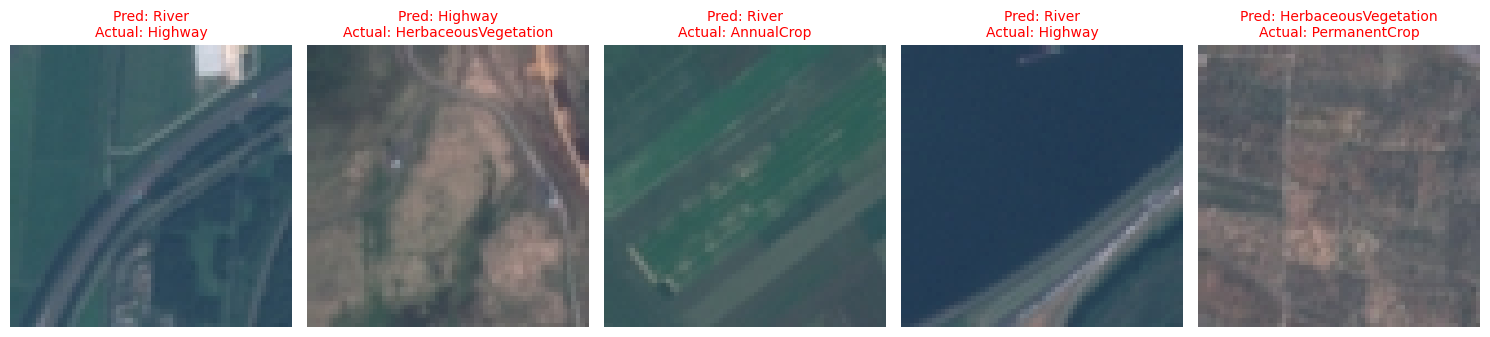

In [ ]:
model.eval()  #Switch training parameters off !!!

misclassified_indices = []

for i in range(len(val_dataset)): 
    image, label = val_dataset[i]
    image_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        predicted_index = torch.argmax(output, dim=1).item()

    if predicted_index != label: 
        misclassified_indices.append(i)

    if len(misclassified_indices) == 5: 
        break
    
index_to_class = {v: k for k, v in label_dict.items()}


mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)  # Un-normalisation
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


fig, axes = plt.subplots(1, 5, figsize=(15, 4))


for i, index in enumerate(misclassified_indices):
    image, label = val_dataset[index]
    image_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        predicted_index = torch.argmax(output, dim=1).item()

    true_label = index_to_class[label]
    predicted_label = index_to_class[predicted_index]


    display_img = image * std + mean 
    display_img = display_img.permute(1, 2, 0).cpu().clamp(0, 1)


    axes[i].imshow(display_img)
    axes[i].axis("off")


    title_color = "green" if predicted_index == label else "red"
    
    axes[i].set_title(f"Pred: {predicted_label}\nActual: {true_label}", color=title_color, fontsize=10)

plt.tight_layout()
plt.show()








### Test Set

In [ ]:
TEST_FOLDER_PATH = ".Data Sets-20260516/public_test_data"

def preprocess_test(data_folder: str) -> pd.DataFrame:
    """
    Creates a DataFrame with the file paths and file names of the test images
    """ 
    data =[]

    for file_name in os.listdir(data_folder):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):   
            data.append({
                "folder": data_folder,
                "file_name": file_name,
                "label": -1
            })

    return pd.DataFrame(data)                     


test_df =  preprocess_test(TEST_FOLDER_PATH)



In [ ]:
test_dataset = SatelliteDataset(
    dataframe=test_df,
    root_dir=".",
    transform=val_transforms
)


test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)


model.load_state_dict(torch.load(r"assets\weights\best_satellite_cnn.pth", map_location='cpu'))
model.eval()

SatelliteResNet9(
  (prep): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (layer1): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (res1): Sequential(
    (0): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, 

In [ ]:
all_test_preds = []

print("Running predictions...")
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        outputs = model(images)

        predicted_classes = outputs.argmax(1)
        all_test_preds.extend(predicted_classes.cpu().numpy())

index_to_class = {v: k for k, v in label_dict.items()}

string_predictions = [index_to_class[pred] for pred in all_test_preds]

test_df["predicted_label"] = string_predictions

print("-\n" )
print("predictions are in! :)")


Running predictions...
-

predictions are in! :)


In [ ]:
submission_df = test_df[["file_name", "predicted_label"]]

submission_df.to_csv("submission.csv", index=False, header=False)

print("submission.csv ready.")
print(submission_df.head())

submission.csv ready.
  file_name       predicted_label
0  1001.jpg  HerbaceousVegetation
1  1002.jpg           Residential
2  1008.jpg         PermanentCrop
3   101.jpg               Highway
4  1034.jpg  HerbaceousVegetation
